This script should show/explain the realtion between the samples and the dimensions of the beta distribution/its CDF and thereby the influence of the expected maximum cosine similarity. 

In [19]:
# Packages 
import matplotlib.pyplot as plt
import numpy as np
import scanpy as sc
import scipy.stats as stats
import seaborn as sns
import yaml
from scipy.integrate import trapezoid
from scipy.special import betainc
from scipy.stats import beta, cumfreq


In [2]:
# Functions
def random_point_on_unit_sphere(n: int) -> np.ndarray:
    point = np.random.randn(n) # Not really sure if that sampling is correct, but as the previous sampling for 2D was the same Sebastian did I trust the website for now. 
    point = point / np.linalg.norm(point)

    return point

## Try to understand the beta distribution/embedded scipy functions

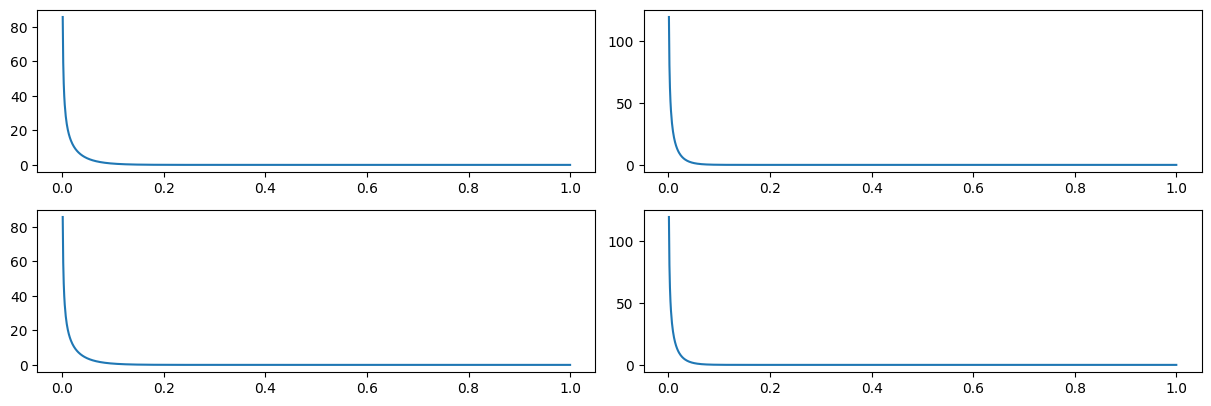

In [4]:
# Choose parameters
n = [50, 100]
d = [50, 100] 
x = np.linspace(0, 1, 1000)

## Model the beta distribution according to the paper explanation and parameter d
fig, axs = plt.subplots(len(n), len(d), figsize=(12, 4), constrained_layout=True)
for i, n_val in enumerate(n):
    for j, d_val in enumerate(d):
        a = 0.5
        b = (d_val - 1) / 2    
        rv = beta(a, b)
        pdf = rv.pdf(x)

        axs[i, j].plot(x, pdf, label='Beta PDF')

plt.show()


/tmp/ipykernel_2362312/4282398513.py:31: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


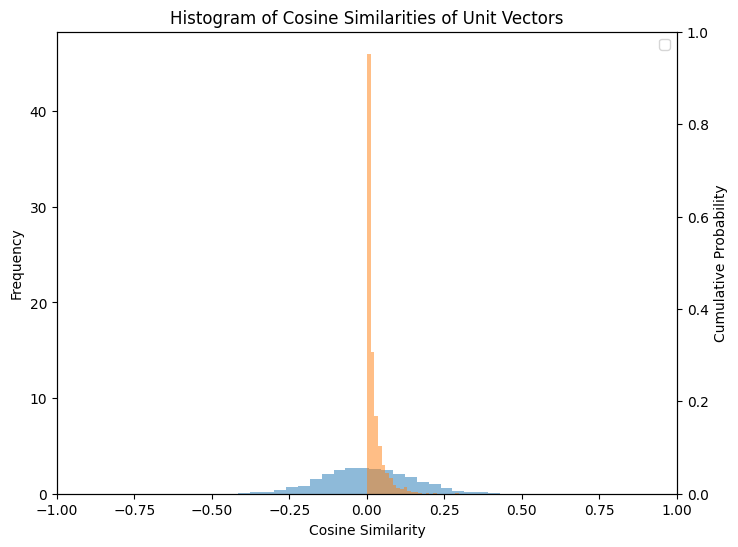

In [5]:
fig, ax1 = plt.subplots(figsize=(8, 6))
ax2 = ax1.twinx()
n=50
d=50
cosine_similarities = []
for re in range(n): 
    random_points = [random_point_on_unit_sphere(d) for _ in range(n)]

    first_item = random_points[re]
    for j in range(1, len(random_points)):
        if j == re:
            continue
        dot_product = np.dot(first_item, random_points[j])
        cosine_similarities.append(dot_product)
    
#r = cumfreq(cosine_similarities, numbins=25, defaultreallimits=(-1, 1))
#x = r.lowerlimit + np.linspace(0, r.binsize * r.cumcount.size, r.cumcount.size)
#cdf = r.cumcount / r.cumcount[-1]
#c = cdf ** n          # added this later after the velocity meeting

beta_like = [x**2 for x in cosine_similarities]

ax1.hist(cosine_similarities, bins=25, label=f"n = {n}", alpha=0.5, density=True)
ax1.hist(beta_like, bins=25, label=f"n = {n} (squared)", alpha=0.5, density=True)
plt.title("Histogram of Cosine Similarities of Unit Vectors")
ax1.set_xlabel("Cosine Similarity")
ax1.set_ylabel("Frequency")
ax2.set_ylabel("Cumulative Probability")
plt.xlim(-1, 1)
ax2.set_ylim(0, 1)
plt.legend()
plt.show()

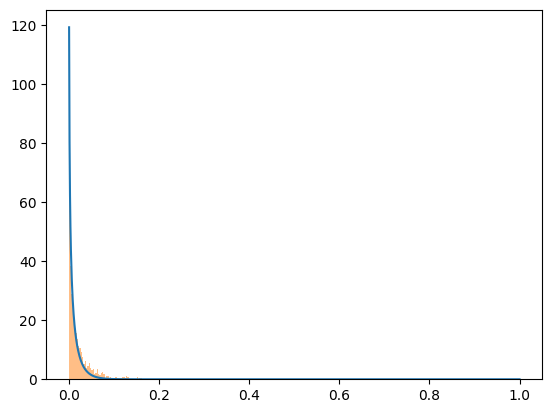

In [6]:
x = np.linspace(0, 1, len(pdf))
plt.plot(x, pdf, label='Beta-like Distribution')
plt.hist(beta_like, bins=100, density=True, alpha=0.5)
plt.show()

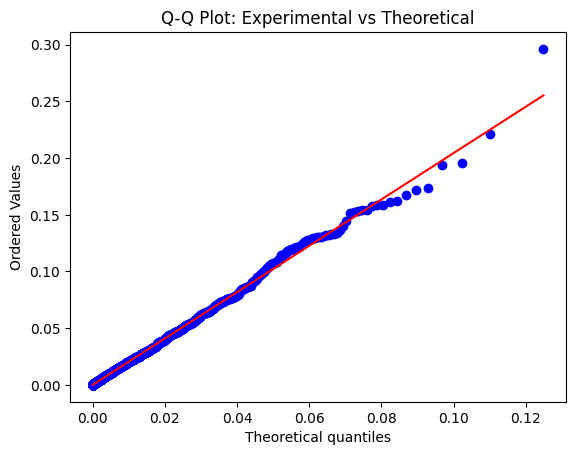

In [7]:
stats.probplot(beta_like, dist=stats.beta, sparams=(a, b), plot=plt)
plt.title("Q-Q Plot: Experimental vs Theoretical")
plt.show()

In [14]:
def get_theoretical_distribution(n:int, d:int):
    x = np.linspace(0, 1, 1000)
    ## Model the beta distribution for this
    a = 0.5
    b = (d - 1) / 2

    rv = beta(a, b)
    pdf = rv.pdf(x**2)

    ## Get the CDF (maybe use incomplete beta function)
    cdf = betainc(a, b, x**2)

    ## Use for the ordered statistics/maximum the CDF to the power of n 
    max_cdf = cdf**n
    ## Calculate the expected value
    expected_max = trapezoid(1 - max_cdf, x**2)
    print(f"Expected maximum = {expected_max:.6f}")
    
    return x, pdf, cdf, max_cdf, expected_max

Expected maximum = 0.037620
Expected maximum = 0.074992
Expected maximum = 0.113660


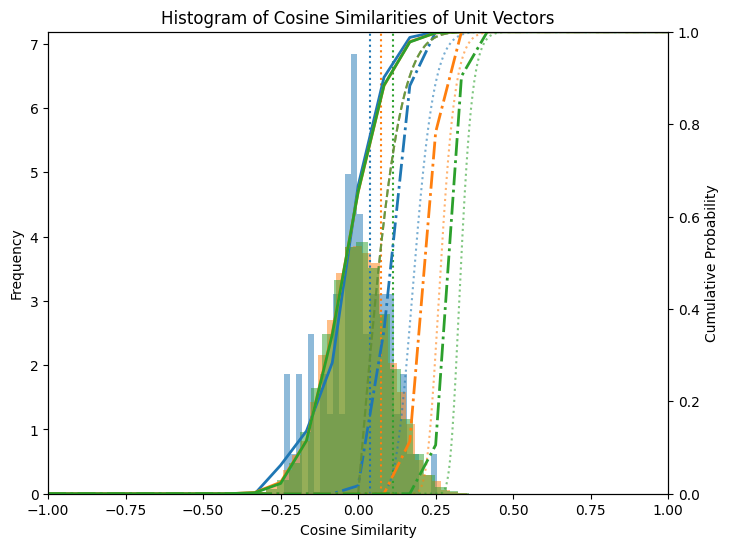

In [15]:
samples = [10, 100, 1000]
d = 100
colors = ['tab:blue', 'tab:orange', 'tab:green']
fig, ax1 = plt.subplots(figsize=(8, 6))
ax2 = ax1.twinx()

for color, n in zip(colors, samples):
    cosine_similarities = []
    for re in range(n): 
        random_points = [random_point_on_unit_sphere(d) for _ in range(n)]

        first_item = random_points[re]
        for j in range(1, len(random_points)):
            if j == re:
                continue
            dot_product = np.dot(first_item, random_points[j])
            cosine_similarities.append(dot_product)
 
    r = cumfreq(cosine_similarities, numbins=25, defaultreallimits=(-1, 1))
    x = r.lowerlimit + np.linspace(0, r.binsize * r.cumcount.size, r.cumcount.size)
    cdf = r.cumcount / r.cumcount[-1]
    c = cdf ** n          # added this later after the velocity meeting

    ax1.hist(cosine_similarities, bins=25, label=f"n = {n}", alpha=0.5, density=True, color=color)
    ax2.plot(x, cdf, label=f"CDF n = {n}", lw=2, linestyle='-', color=color)
    ax2.plot(x, c, label=fr"$F(x)^{{{n}}}$", lw=2, linestyle='dashdot', color=color) # also added this later as the plotting of F(x)^n

    x, pdf, cdf, max_cdf, expected_max = get_theoretical_distribution(n, d)
    #ax1.plot(x, pdf,color=color,  label='Beta PDF')
    ax2.plot(x, cdf, color=color, linestyle= "dashed", alpha=0.6, label='beta cdf')
    ax2.plot(x, max_cdf, color=color, linestyle='dotted', alpha=0.6, label='max CDF')
    ax1.axvline(expected_max, color=color, linestyle='dotted', label=f'E[max] = {expected_max:.3f}')

plt.title("Histogram of Cosine Similarities of Unit Vectors")
ax1.set_xlabel("Cosine Similarity")
ax1.set_ylabel("Frequency")
ax2.set_ylabel("Cumulative Probability")
plt.xlim(-1, 1)
ax2.set_ylim(0, 1)
#plt.legend()
plt.show()

Here the figures were partially already kind of prepared to place in the thesis

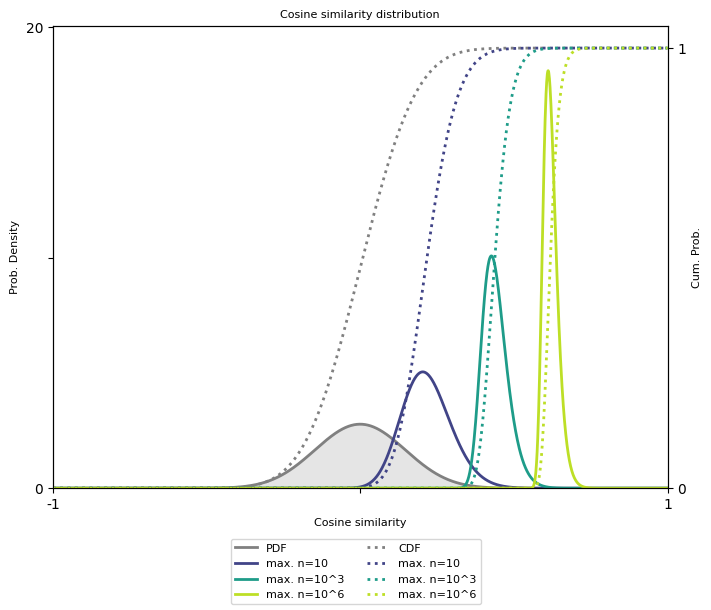

In [16]:
# Set parameters
d = 50
n_values = [10, 1000, 1000000]

# Set parameter for beta distribution
a = 0.5
b = (d - 1) / 2  
# Set arbitraty cosine similarity distribution x values 
x = np.linspace(-1, 1, 2000) 
x[x == 0] = 1e-10 # Take 0 out as division by zero woudl be probalamtic

fig, ax1 = plt.subplots(figsize=(7, 6), constrained_layout=True)
ax2 = ax1.twinx()  

# Create baseline cosine similarity distribution
pdf_base = np.abs(x) * beta.pdf(x**2, a, b)
# Create baseline CDF of the cosine similarity
cdf_base = np.where(x >= 0, 
                    0.5 + 0.5 * beta.cdf(x**2, a, b), 
                    0.5 - 0.5 * beta.cdf(x**2, a, b))

# Plot baseline distributions
ax1.plot(x, pdf_base, color='gray', lw=2, label="PDF")
ax1.fill_between(x, pdf_base, color='gray', alpha=0.2)
ax2.plot(x, cdf_base, color='gray', lw=2, linestyle=':', label="CDF")

# Apply the cell number to the maximum cose similarity 
colors = plt.cm.viridis(np.linspace(0.2, 0.9, len(n_values)))
for n, color in zip(n_values, colors):
    # The CDF of the maximum: F(x)^n
    cdf_max = cdf_base ** n
    # The PDF of the maximum: derivative of F(x)^n
    pdf_max = n * (cdf_base ** (n - 1)) * pdf_base
    # Plot
    n_str = f"10^{int(np.log10(n))}" if int(np.log10(n)) > 1 else str(n)
    ax2.plot(x, cdf_max, color=color, lw=2, linestyle=':', label=f"max. n={n_str}")
    ax1.plot(x, pdf_max, color=color, lw=2, label=f"max. n={n_str}")

# Left over plotting
ax1.set_ylabel("Prob. Density", fontsize=8)
ax1.set_ylim(0,20.05)
ax1.set_yticks([0, 10, 20])
ax1.set_yticklabels(['0', '', '20'])
ax2.set_ylabel("Cum. Prob.", fontsize=8)
ax2.set_ylim(0,1.05)
ax2.set_yticks([0, 1])
ax2.set_yticklabels(['0', '1'])

ax1.set_xlabel("Cosine similarity", fontsize=8)
ax1.set_xlim(-1,1)
ax1.set_xticks([-1, 0, 1.0])
ax1.set_xticklabels(['-1', '', '1'])

# Combine legends from both axes into one box
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
fig.legend(lines1 + lines2, labels1 + labels2, loc='outside lower center', ncol=2, fontsize=8)

ax1.set_title("Cosine similarity distribution", fontsize=8, )
plt.show()

In [21]:
datasets = {
        #"Pancreas_dynamical": "../configs/pancreas_dynamic.yaml",
        #"Pancreas_stochastic": "../configs/pancreas_stochastic.yaml",
        #"Dentate_gyrus": "../configs/dentategyrus.yaml",
        #"Gastrulation_erythroid": "../configs/gastrulation.yaml",
        "Bone_marrow": "../configs/bonemarrow.yaml",
        #"PBMC": "../configs/pbmc.yaml",
        "Covid": "../configs/covid.yaml",
        #"Retinal_development": "../configs/retinal_development.yaml",
        "Human_HSC": "../configs/humanHSC.yaml",
        #"RPE_1": "../configs/noEmbedding/intestinal_organoids.yaml",
        #"Hindbrain_mouse": "../configs/noEmbedding/hindbrain.yaml",
        #"Oligodendrocyte_mouse": "../configs/noEmbedding/oligodendrocyte.yaml",
        #"Bone_marrow_mouse": "../configs/noEmbedding/mouse_bonemarrow.yaml",
        #"Cerebral_cortex_human": "../configs/noEmbedding/human_cerebral.yaml",
        #"Hematopoiesis_mouse": "../configs/noEmbedding/mouse_hema.yaml",
        "Spermatogenisis": "../configs/noEmbedding/spermatogenesis.yaml",
        #"Old_brain": "../configs/noEmbedding/old_brain.yaml",
        #"Prefrontal_cortex": "../configs/noEmbedding/pfc.yaml",
        #"Intestinal_organoids":"../configs/noEmbedding/GSE128365.yaml",
        #"Zebra_NMP": "../configs/noEmbedding/zebra_NMP.yaml",  
    }

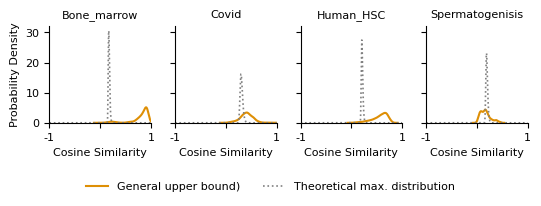

In [23]:
# Load datasets
cm = 1 / 2.54 
fig, axes = plt.subplots(1, 4, figsize=(14 * cm, 5* cm), sharey=True)
i=0
palette = sns.color_palette("colorblind", 5)
for name, path in datasets.items():
    with open(path, "r") as f:
        config = yaml.safe_load(f)

    adata = sc.read(config['path'])
    general = adata.obsm['general_bound']
    upper = adata.obsm['upper_max_neighbors'] 
    n = adata.n_obs
    d = np.sum(adata.var.velocity_genes)

    # Set parameter for beta distribution
    a = 0.5
    b = (d - 1) / 2  
    # Set arbitraty cosine similarity distribution x values 
    x = np.linspace(-1, 1, 2000) 
    x[x == 0] = 1e-10 # Take 0 out as division by zero woudl be probalamtic

    # Construct CDF of cos sim distribution with the beta distribution for X^2 adn for the maximum
    cdf = np.where(x >= 0, 
                   0.5 + 0.5 * beta.cdf(x**2, a, b), 
                   0.5 - 0.5 * beta.cdf(x**2, a, b))
    cdf_max = cdf**n

    # Construct PDF of cos sim distribution with the beta distribution for X^2 adn for the maximum
    pdf = np.abs(x) * beta.pdf(x**2, a, b)
    pdf_max = n * (cdf ** (n - 1)) * pdf

    '''
    # This part of code was important for the personal understanding of the corelation cos sim and beta distribution
    # Construct Distribution with random point sampling 
    cosine_similarities = []
    for re in range(n): 
        random_points = [random_point_on_unit_sphere(d) for _ in range(n)]

        first_item = random_points[re]
        for j in range(1, len(random_points)):
            if j == re:
                continue
            dot_product = np.dot(first_item, random_points[j])
            cosine_similarities.append(dot_product)
    r_sampled = cumfreq(cosine_similarities, numbins=2000, defaultreallimits=(-1, 1))
    x_sampled = r_sampled.lowerlimit + np.linspace(0, r_sampled.binsize * r_sampled.cumcount.size, r_sampled.cumcount.size)
    cdf_sampled = r=r_sampled.cumcount / r_sampled.cumcount[-1]
    c = cdf_sampled ** n   
    '''

    # 5. Plotting
    sns.kdeplot(general, clip=(-1, 1), fill=False, linewidth=1.5, color=palette[1], # Adjust palette as needed
                label="General upper bound)", ax=axes[i])
    
    # Plot the theoretical maximum distribution
    axes[i].plot(x, pdf_max, label=f"Theoretical max. distribution", color="gray", linestyle=":", linewidth=1.2)
    #ax.plot(x, cdf_max, label=f"Theoretical Max Dist (n={n}, d={d})", color="blue", linestyle="--")
    #ax.plot(x_sampled, c)
    
    axes[i].set_xlim(-1, 1)
    axes[i].set_xticks([-1, 0, 1])
    axes[i].set_xticklabels(['-1', '', '1'])
    axes[i].set_xlabel("Cosine Similarity", fontsize=8)
    
    # Only show the y-axis label on the first plot
    if i == 0:
        axes[i].set_ylabel("Probability Density", fontsize=8)
    else:
        axes[i].set_ylabel(" ", fontsize=8 )
        
    axes[i].set_title(name, fontsize = 8)
    axes[i].tick_params(axis='both', which='major', labelsize=8)
    
    i+=1

# Clean up top and right borders for a cleaner, modern look
sns.despine(fig)

# Extract handles and labels to place a single, clean shared legend at the bottom
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', bbox_to_anchor=(0.5, -0.05), ncol=2, fontsize=8, frameon=False)

# Adjust layout to make room for the legend without overlapping titles or axes
plt.tight_layout()
plt.subplots_adjust(bottom=0.35) 
plt.show()